<a href="https://colab.research.google.com/github/loulakanani/machine-learning-in-finance/blob/main/Demographic_Vulnerabilities_and_Payment_Delay_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Demographic Vulnerabilities and Payment Delay Patterns**

In [56]:
#1st question: A short financial question written in one paragraph.

Which specific demographic profile represents the highest risk of default, and within this riskiest group, is the default driven by chronic historical delays or sudden isolated incidents?

In [57]:
#2 Source, access date, observation unit, target, and units.

* **Source:** Canonical UCI credit-risk dataset.
* **Access Date:** 23 October 2026.
* **Observation Unit:** One (1) credit card client record.
* **Target:** default_next_month (1 = Default, 0 = No default).
* **Units:** Financial amounts (LIMIT, BILL, PAY) are in New Taiwan Dollars (NT$). Age is in years.

In [58]:
#3 Shape, data types, missingness, duplicate rows, and target balance.

In [59]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


credit = pd.read_excel("default of credit card clients.xls", header=1)

audit = pd.Series({
    "rows": len(credit),
    "columns": credit.shape[1],
    "missing_cells": credit.isna().sum().sum(),
    "duplicate_rows": credit.duplicated().sum(),
    "unique_ids": credit["ID"].nunique()
    })

print(audit)

print(credit["default payment next month"].value_counts().to_dict())


rows              30000
columns              25
missing_cells         0
duplicate_rows        0
unique_ids        30000
dtype: int64
{0: 23364, 1: 6636}


In [60]:
#4 Descriptive statistics for at least six variables.

In [61]:
variables = ["LIMIT_BAL", "AGE", "SEX", "EDUCATION", "MARRIAGE", "PAY_0"]

summary = (
    credit[variables]
    .describe()
    .T
    )

summary["IQR"] = summary["75%"] - summary["25%"]
summary = summary.round(2)

print(summary)

             count       mean        std      min      25%       50%  \
LIMIT_BAL  30000.0  167484.32  129747.66  10000.0  50000.0  140000.0   
AGE        30000.0      35.49       9.22     21.0     28.0      34.0   
SEX        30000.0       1.60       0.49      1.0      1.0       2.0   
EDUCATION  30000.0       1.85       0.79      0.0      1.0       2.0   
MARRIAGE   30000.0       1.55       0.52      0.0      1.0       2.0   
PAY_0      30000.0      -0.02       1.12     -2.0     -1.0       0.0   

                75%        max       IQR  
LIMIT_BAL  240000.0  1000000.0  190000.0  
AGE            41.0       79.0      13.0  
SEX             2.0        2.0       1.0  
EDUCATION       2.0        6.0       1.0  
MARRIAGE        2.0        3.0       1.0  
PAY_0           0.0        8.0       1.0  


In [62]:
#5 One groupby or pivot_table comparison with group counts.

In [63]:
# Grouping of borrowers
grouped_all = credit.groupby(["SEX", "EDUCATION", "MARRIAGE"], observed=False).agg(
    borrowers=("ID", "size"),
    default_rate=("default payment next month", "mean")
).round(4)

# Sort to see the highest risk at the top
print(grouped_all.sort_values(by="default_rate", ascending=False).head(5))

# Filtering for the riskiest group
riskiest_group = credit[(credit["SEX"] == 1) & (credit["EDUCATION"] == 1) & (credit["MARRIAGE"] == 3)]
print(riskiest_group["PAY_0"].value_counts().sort_index())

                        borrowers  default_rate
SEX EDUCATION MARRIAGE                         
1   1         3                30        0.3333
    3         3                36        0.3056
    2         3                63        0.3016
2   6         2                10        0.3000
1   3         1              1048        0.2891
PAY_0
-2     2
-1     4
 0    19
 1     4
 3     1
Name: count, dtype: int64


In [64]:
#6 Two labelled plots and one paragraph interpreting each

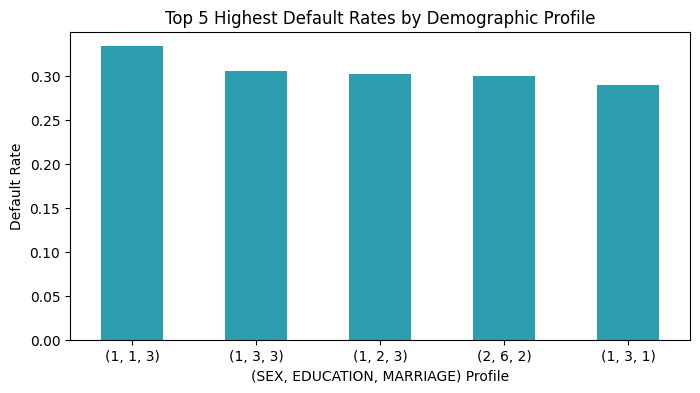

In [65]:
# The 5 most dangerous demographic profiles
plt.figure(figsize=(8, 4))

top_risk = grouped_all.sort_values(by="default_rate", ascending=False).head(5)
top_risk["default_rate"].plot(kind="bar", color="#2D9DB0")

plt.title("Top 5 Highest Default Rates by Demographic Profile")
plt.ylabel("Default Rate")
plt.xlabel("(SEX, EDUCATION, MARRIAGE) Profile")
plt.xticks(rotation=0)
plt.show()

We observe the 5 riskiest groups. The category of men who hold a postgraduate degree and fall into the "other" family status category exhibits a default rate of 33%.

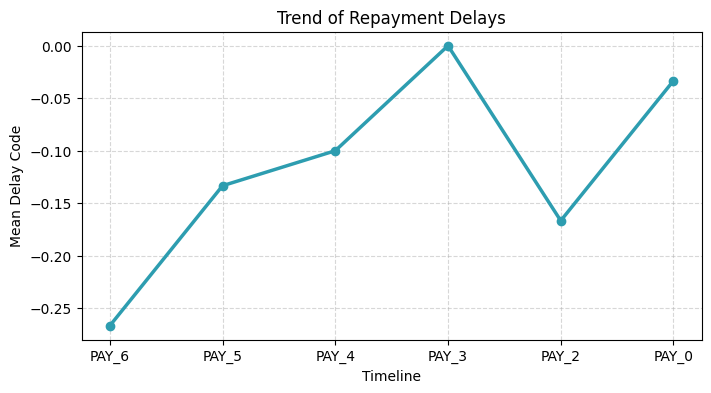

In [66]:
# The distribution of delays for risk
pay_months = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]
mean_delays = riskiest_group[pay_months].mean()

plt.figure(figsize=(8, 4))
mean_delays.plot(kind="line", marker="o", color="#2D9DB0", linewidth=2.5)

plt.title("Trend of Repayment Delays")
plt.ylabel("Mean Delay Code")
plt.xlabel("Timeline")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

We observe a steady and continuous upward trend. If the default were due to a sudden event, the line would have remained flat and close to zero throughout the six-month period. Conversely, the gradual rise demonstrates that the borrowers in this group experienced systematic and escalating repayment difficulties, month after month. The default is driven by a long-standing, progressive deterioration rather than by a sudden, isolated incident.

In [67]:
# 6 One data-quality limitation and one reason the result is not causal.

Data-Quality Limitation: Although there are no empty cells (0 missing values), the negative values ​​(-1, -2) and the value 0 in the PAY_ variables introduce ambiguity regarding the UCI documentation; it is unclear whether these represent advance payments, full settlements, or a lack of activity.
Non-Causal Nature: The findings are purely descriptive. The correlation between demographic profiles and default does not constitute a causal claim, as the groups differ in terms of critical omitted factors, such as income, occupation, or credit limit.

In [68]:
# Use of Artificial Intelligence

Generative artificial intelligence was used as an interactive coding assistant to complete this work. The AI ​​helped simplify and verify the accuracy of Pandas groupby and describe commands, ensured the correct formatting parameters for labeled plots, and assisted with the linguistic editing of the written economic interpretations all without altering the underlying research logic or the final selection of variables.